# Annotate Video with Detections

---

[![Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roboflow/supervision/blob/develop/docs/notebooks/annotate-video-with-detections.ipynb)

One of the most common requirements of computer vision applications is detecting objects in images and displaying bounding boxes around those objects. In this cookbook we'll walk through the steps on how to utilize the open source Roboflow ecosystem to accomplish this task on a video. Let's dive in!

## Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [1]:
!nvidia-smi

Fri Feb 23 03:15:00 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla V100-SXM2-16GB           Off | 00000000:00:04.0 Off |                    0 |
| N/A   33C    P0              24W / 300W |      0MiB / 16384MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

## Installing Dependencies

In this cookbook we'll be utilizing the open source packages [RF-DETR](https://github.com/roboflow/rf-detr) and [Supervision](https://supervision.roboflow.com/latest/) to accomplish our goals. Let's get those installed in our notebook with pip.

In [ ]:
!pip install -q rfdetr "supervision"

## Download a Video Asset

First, let's download a video that we can detect objects in. Supervision comes with a great utility called Assets to help us hit the ground running. When we run this script, the video is saved in our local directory and can be accessed with the variable `path_to_video`.

In [ ]:
from supervision.assets import download_assets, VideoAssets

# Download a supervision video asset
path_to_video = download_assets(VideoAssets.PEOPLE_WALKING)

As a result, we've downloaded a video. Let's take a look at the video below.  Keep in mind that the video preview below works only in the web version of the cookbooks and not in Google Colab.

<div style="display: flex; justify-content: center;">
    <video controls width="1000"">
        <source
            src="https://media.roboflow.com/supervision/video-examples/people-walking.mp4"
            type="video/mp4"
        >
    </video>
</div>






## Detecting Objects

For this example, the objects in the video that we'd like to detect are people. In order to display bounding boxes around the people in the video, we first need a way to detect them. We'll be using the open source [RF-DETR](https://github.com/roboflow/rf-detr) package for this task. RF-DETR is a real-time object detection model pre-trained on COCO, which includes the `person` class, and it can be fine-tuned on your own dataset. We'll also utilize a few utilities for working with our video data from the [Supervision](https://github.com/roboflow/supervision) package.

In [ ]:
import supervision as sv
from rfdetr import RFDETRSmall


# Load a pre-trained RF-DETR Small model. The COCO weights are downloaded on first use.
model = RFDETRSmall()

# Create a frame generator and video info object from supervision utilities.
frame_generator = sv.get_video_frames_generator(path_to_video)

# Yield a single frame from the generator.
frame = next(frame_generator)

# Run inference on our frame. RF-DETR expects RGB, while OpenCV frames are BGR,
# and `predict()` returns a supervision detections object directly.
detections = model.predict(frame[:, :, ::-1])

# Pretty Print the resulting detections.
from pprint import pprint
pprint(detections)

Detections(xyxy=array([[1143.5518 ,  950.5385 , 1242.2743 , 1079.1633 ],
       [1409.8306 ,  703.28436, 1521.0435 ,  888.4613 ],
       [ 666.4424 ,  651.18085,  743.5537 ,  854.5226 ],
       [ 706.9658 ,  239.91205,  767.97394,  390.88513],
       [1143.9033 ,  507.24393, 1206.1697 ,  657.4894 ],
       [1446.9978 ,  320.25446, 1517.628  ,  485.71707],
       [ 751.4935 ,  451.91577,  822.4753 ,  624.8058 ],
       [ 568.6809 ,  270.05954,  629.39374,  412.15704],
       [1463.4534 ,  473.35873, 1542.5447 ,  643.097  ],
       [ 261.3227 ,  439.15036,  331.34882,  610.288  ],
       [  33.94771,  795.29553,  140.23592,  989.59894],
       [ 923.8853 ,  171.97887,  987.89575,  306.1997 ]], dtype=float32),
           mask=None,
           confidence=array([0.85783094, 0.7923683 , 0.7718598 , 0.68213624, 0.6771343 ,
       0.6758359 , 0.6585397 , 0.6485612 , 0.6228658 , 0.60987365,
       0.601504  , 0.5252725 ], dtype=float32),
           class_id=array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

First, we load our model with `RFDETRSmall()`. The pre-trained COCO weights are downloaded automatically the first time it runs, and no API key is needed. To use your own fine-tuned weights instead, pass them with `RFDETRSmall(pretrain_weights="path/to/checkpoint.pth")`.

We then create a `frame_generator` object and yield a single frame for inference using `next()`. We pass our frame to `model.predict()` to run inference. OpenCV reads frames as BGR while RF-DETR expects RGB, so we reverse the channel order with `frame[:, :, ::-1]`. `predict()` already returns an `sv.Detections` object, so no conversion step is needed. Lastly we print our detections to show we are in fact detecting a few people in the frame!

## Annotaing the Frame with Bounding Boxes

Now that we're detecting images, let's get to the fun part. Let's annotate the frame and display the bounding boxes on the frame.

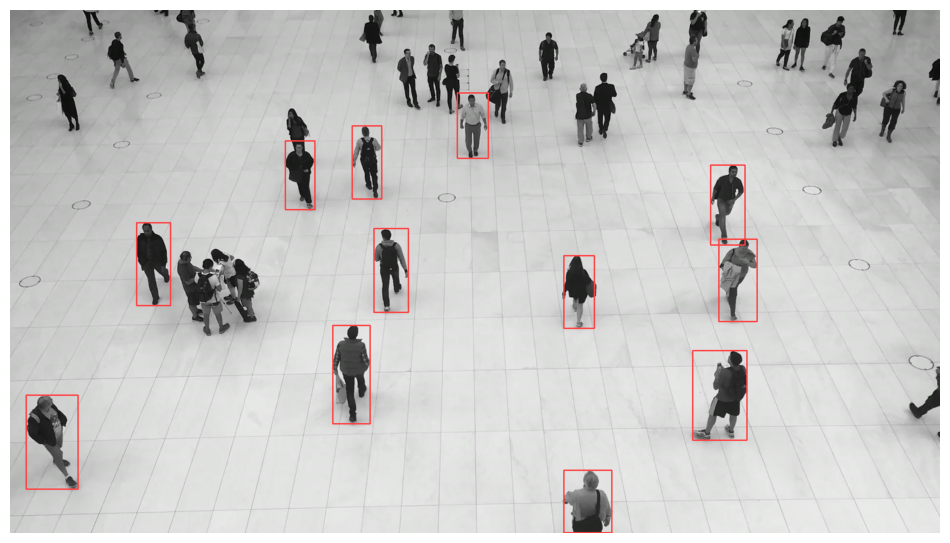

In [5]:
# Create a bounding box annotator object.
box_annotator = sv.BoxAnnotator()

# Annotate our frame with detections.
annotated_frame = box_annotator.annotate(scene=frame.copy(), detections=detections)

# Display the frame.
sv.plot_image(annotated_frame)

Notice that we create a `box_annotator` variable by initalizing a [BoxAnnotator](https://supervision.roboflow.com/latest/detection/annotators/#boxannotator). We can change the color and thickness, but for simplicity we keep the defaults. There are a ton of easy to use [annotators](https://supervision.roboflow.com/latest/detection/annotators/) available in the Supervision package other than a bounding box that are fun to play with.

## Saving Bounding Boxes to a Video

Let's wrap up our code by utilizing a `VideoSink` to draw bounding boxes and save the resulting video. Take a peak at the final code example below. This can take a couple minutes deppending on your runtime and since since we're processing a full video. Feel free to skip ahead to see the resulting video.

In [ ]:
from tqdm import tqdm

# Create a video_info object for use in the VideoSink.
video_info = sv.VideoInfo.from_video_path(video_path=path_to_video)

# Create a VideoSink context manager to save our frames.
with sv.VideoSink(target_path="output.mp4", video_info=video_info) as sink:

    # Iterate through frames yielded from the frame_generator.
    for frame in tqdm(frame_generator, total=video_info.total_frames):

        # Run inference on our frame. The result is already a detections object.
        detections = model.predict(frame[:, :, ::-1])

        # Apply bounding box to detections on a copy of the frame.
        annotated_frame = box_annotator.annotate(
            scene=frame.copy(),
            detections=detections
        )

        # Write the annotated frame to the video sink.
        sink.write_frame(frame=annotated_frame)

<div style="display: flex; justify-content: center;">
  <video controls width="1000">
      <source
          src="https://storage.googleapis.com/com-roboflow-marketing/supervision/cookbooks/annotate-video-with-detections.mp4"
          type="video/mp4"
      >
  </video>
</div>
<br>


In the code above we've created a`video_info` variable to pass information about the video to our `VideoSink`. The `VideoSink` is a cool little context manager that allows us to `write_frames()` to a video output file. We're also optionally using `tqdm` to display a progress bar with a % complete. We only scratched the surface of all of the customizable Annotators and additional features that Supervision and RF-DETR have to offer. Stay tuned for more cookbooks on how to take advantage of them in your computer vision applications. Happy building! 🚀